# 5 · Model preservation and communication costs

**Question:** Do transferred models remain identical, and how large is the measured overhead?

For readers who want to understand the ML integration experiment without
building native libraries. We inspect existing preservation checks, count
messages and separate model payload bytes from added protection bytes.
These notebooks present the fixed benchmark's measurements; the transport
implementation and its algorithm settings are documented in [Methods](../docs/methods.md).

**Route:** paired workloads → preserved states → bytes → measurement boundaries.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'fedecg/models.py').is_file())
sys.path.insert(0, str(ROOT))
from notebooks._support import CLASSES, COLORS, NAMES, read_table, read_json, setup, finish
setup()
%matplotlib inline

## Pair the learning workload across transfer policies

Two fitted model recipes × three learning seeds give **six learning trajectories**.
Each is executed with unprotected, fixed-L3 and adaptive transfer policies,
with three timing repetitions. This produces 54 executions. A timing repeat
does not create a new predictive trial.

Each of 30 rounds has 17 full-model downloads and 17 full-model uploads:
1,020 messages per execution. Received bytes are decoded into the model used
for training or aggregation.

In [2]:
preservation = read_json('integration_preservation.json')
checks = pd.DataFrame(preservation['comparisons'])
display(checks[['model', 'seed', 'matched_rounds', 'matched_executions',
                'maximum_parameter_difference', 'all_round_hashes_identical']])
assert len(checks) == 6 and checks.all_round_hashes_identical.all()
assert (checks.maximum_parameter_difference == 0).all()
assert preservation['runs'] == 2 * 3 * 3 * 3 == 54
messages = 30 * 17 * 2
print(f'{messages:,} full-model messages per execution; six paired learning trajectories.')

,model,seed,matched_rounds,matched_executions,maximum_parameter_difference,all_round_hashes_identical
0,mlp,11,30,9,0.0,True
1,mlp,22,30,9,0.0,True
2,mlp,33,30,9,0.0,True
3,mlp_rr,11,30,9,0.0,True
4,mlp_rr,22,30,9,0.0,True
5,mlp_rr,33,30,9,0.0,True


1,020 full-model messages per execution; six paired learning trajectories.


All round hashes match across the paired policies; complete state arrays are
also retained for one timing repetition. Final states reproduce the corresponding
unprotected learners. This checks model preservation. It is separate from the
classifier's ability to recognize rare ECG classes.

## A smaller overhead is not the same percentage change in total traffic

Total serialized component bytes equal raw FP32 parameter bytes plus added
protection bytes. The declared adaptive trace spends less on protection, but
the model parameters dominate the total. The plots and table use decimal MB
(1 MB = 1,000,000 bytes). These are measured serialized components, excluding
network stack headers and a network deployment's additional traffic.

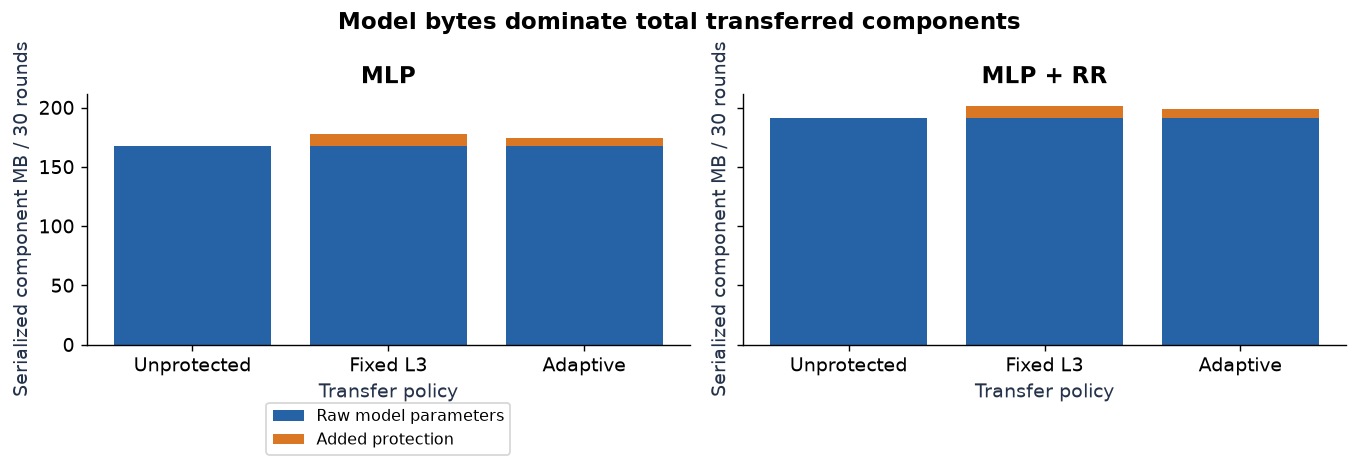

In [3]:
transfer = read_table('integration_summary.csv')
policies = ['none', 'fixed_L3', 'adaptive']
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model in zip(axes, ['mlp', 'mlp_rr']):
    frame = transfer.query('model == @model').set_index('policy').loc[policies]
    raw = frame.raw_bytes_mean / 1e6
    extra = frame.protection_extra_bytes_mean / 1e6
    np.testing.assert_allclose(frame.raw_bytes_mean + frame.protection_extra_bytes_mean,
                               frame.wire_component_bytes_mean)
    ax.bar(policies, raw, label='Raw model parameters', color=COLORS[0])
    ax.bar(policies, extra, bottom=raw, label='Added protection', color=COLORS[1])
    ax.set(title=NAMES[model], xlabel='Transfer policy', ylabel='Serialized component MB / 30 rounds')
    ax.set_xticks(range(3), ['Unprotected', 'Fixed L3', 'Adaptive'])
axes[0].legend(loc='upper center', bbox_to_anchor=(.5, -.2), fontsize=9)
fig.suptitle('Model bytes dominate total transferred components', fontsize=13, fontweight='bold')
finish(fig)

In [4]:
rows = []
for model in ['mlp', 'mlp_rr']:
    frame = transfer.query('model == @model').set_index('policy')
    fixed, adaptive = frame.loc['fixed_L3'], frame.loc['adaptive']
    rows.append({'Model': NAMES[model], 'Raw MB': fixed.raw_bytes_mean / 1e6,
                 'Fixed protection MB': fixed.protection_extra_bytes_mean / 1e6,
                 'Adaptive protection MB': adaptive.protection_extra_bytes_mean / 1e6,
                 'Protection reduction %': 100 * (1 - adaptive.protection_extra_bytes_mean / fixed.protection_extra_bytes_mean),
                 'Total reduction %': 100 * (1 - adaptive.wire_component_bytes_mean / fixed.wire_component_bytes_mean)})
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(3))

,Raw MB,Fixed protection MB,Adaptive protection MB,Protection reduction %,Total reduction %
Model,,,,,
MLP,167.137,10.604,7.305,31.114,1.856
MLP + RR,191.095,10.604,7.305,31.114,1.636


The added protection decreases by about 31.11%, while total component traffic
decreases by about 1.86% for MLP and 1.64% for MLP + RR. Always state the denominator.
The required-level trace is synthetic and fixed for pairing, so these savings
describe that trace rather than arbitrary deployment workloads.

## Host timing answers a bounded systems question

The recorded means below describe sequential host execution on one machine.
Training, serialization, transfer-library calls and aggregation are timed
separately. They do not measure network latency, parallel clients or physical
device energy. Repeated timing runs share their learning schedules.

,model,policy,Host seconds / 30 rounds,Training seconds / 30 rounds,Protection seconds / 30 rounds
0,MLP,adaptive,3.2331,2.6014,0.5657
1,MLP,fixed_L3,3.3017,2.5823,0.6547
2,MLP,none,2.6844,2.6229,0.0012
3,MLP + RR,adaptive,4.6456,3.9208,0.6185
4,MLP + RR,fixed_L3,4.7474,3.9229,0.7178
5,MLP + RR,none,4.0973,3.9940,0.0013


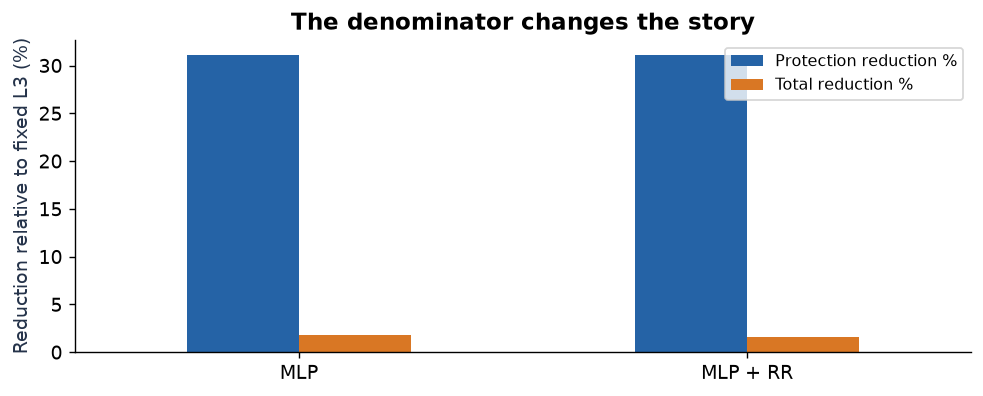

In [5]:
timing = transfer[['model', 'policy', 'elapsed_rounds_seconds_mean',
                   'training_seconds_mean', 'transport_seconds_mean']].copy()
timing['model'] = timing.model.map(NAMES)
display(timing.rename(columns={'elapsed_rounds_seconds_mean': 'Host seconds / 30 rounds',
    'training_seconds_mean': 'Training seconds / 30 rounds', 'transport_seconds_mean': 'Protection seconds / 30 rounds'}).round(4))
fig, ax = plt.subplots(figsize=(8, 3.3))
columns = ['Protection reduction %', 'Total reduction %']
comparison[columns].plot.bar(ax=ax, color=COLORS[:2], rot=0)
ax.set(ylabel='Reduction relative to fixed L3 (%)', xlabel='', title='The denominator changes the story')
ax.legend(fontsize=9); finish(fig)

### Try it: would a larger model change the percentage of total bytes saved?

Keep protection overhead fixed and double the MLP raw parameter bytes. Compute
the same total-traffic percentage. This is arithmetic sensitivity, not a measured
additional model or a revised transport benchmark.

In [6]:
row = comparison.loc['MLP']
raw = row['Raw MB'] * 2
fixed = row['Fixed protection MB']; adaptive = row['Adaptive protection MB']
reduction = 100 * (1 - (raw + adaptive) / (raw + fixed))
print(f'Toy doubled-payload total reduction: {reduction:.2f}%')
# The same absolute overhead saving is a smaller fraction of a larger payload.

Toy doubled-payload total reduction: 0.96%


**Takeaway:** paired model-state equality and transparent byte accounting make
the integration experiment inspectable. Neither establishes predictive improvement
or deployment performance on its own.

**Optional extension:** follow [the reproduction guide](../docs/reproduction.md)
to fetch the full reference archive and verify every round's hashes and retained
arrays with `scripts/verify_reference.py`.

**Return:** [Notebook guide and evidence map](README.md)